# Notebook 5 — Business Insights with SHAP

The XGBoost model predicts well, but a manager also needs to know **why**. SHAP (SHapley Additive
exPlanations) splits every prediction into the contribution of each feature. Averaging the size of those
contributions shows which factors drive predicted demand the most.

SHAP shows what the model relies on. It is not proof of cause and effect.

In [1]:
import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

sys.path.insert(0, "../src")
import pricing_engine as engine

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
df = pd.read_csv("../data/processed_restaurant_sales_data.csv.gz")
df["Date"] = pd.to_datetime(df["Date"])

model = joblib.load("../models/xgboost_demand_model.pkl")

X = df[list(model.feature_names_in_)]
y = df["Units_Sold"]

print("Dataset shape:", df.shape)
print("Model expects:", len(model.feature_names_in_), "features | data provides:", X.shape[1])

Dataset shape: (174960, 46)
Model expects: 37 features | data provides: 37


In [3]:
preprocessor = model.named_steps["preprocessor"]
xgb_model = model.named_steps["model"]

sample_X = X.sample(n=2000, random_state=42)
sample_X_processed = preprocessor.transform(sample_X)

print("Sample shape:", sample_X.shape)
print("Processed sample shape:", sample_X_processed.shape)
print("Mean predicted demand in sample:", round(float(model.predict(sample_X).mean()), 2), "units")

Sample shape: (2000, 37)
Processed sample shape: (2000, 115)
Mean predicted demand in sample: 32.71 units


In [4]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(sample_X_processed)

print("SHAP analysis completed.")
print("SHAP values shape:", shap_values.shape)

SHAP analysis completed.
SHAP values shape: (2000, 115)


In [5]:
processed_feature_names = list(sample_X_processed.columns)

shap_importance = (
    pd.DataFrame({"Feature": processed_feature_names, "Mean_Abs_SHAP": np.abs(shap_values).mean(axis=0)})
    .sort_values("Mean_Abs_SHAP", ascending=False)
    .reset_index(drop=True)
)
shap_importance.head(20)

,Feature,Mean_Abs_SHAP
0,Avg_Item_Demand,14.943719
1,Footfall_Index,5.953100
2,Price_Index,1.978234
3,Base_Price,1.695591
4,Avg_Item_Price,1.367479
5,Promotion_Depth,1.126901
6,Selling_Price,0.641418
7,Competitor_Price_Ratio,0.583993
8,Temperature,0.447144
9,Competitor_Price_Gap,0.435365


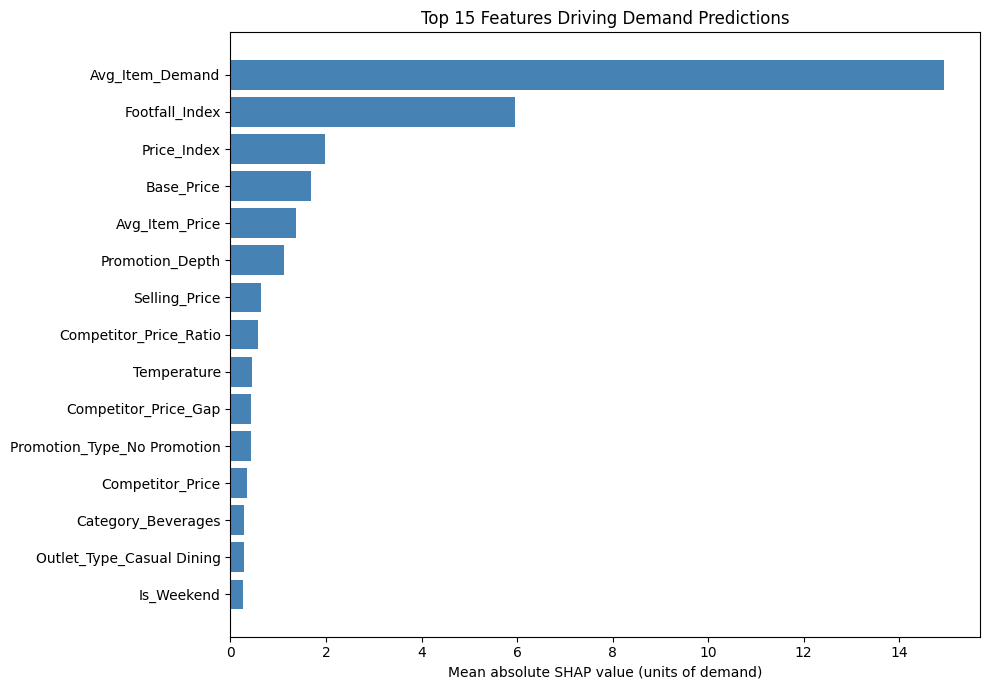

In [6]:
top_features = shap_importance.head(15).sort_values("Mean_Abs_SHAP")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Mean_Abs_SHAP"], color="steelblue")
plt.xlabel("Mean absolute SHAP value (units of demand)")
plt.title("Top 15 Features Driving Demand Predictions")
plt.tight_layout()
plt.show()

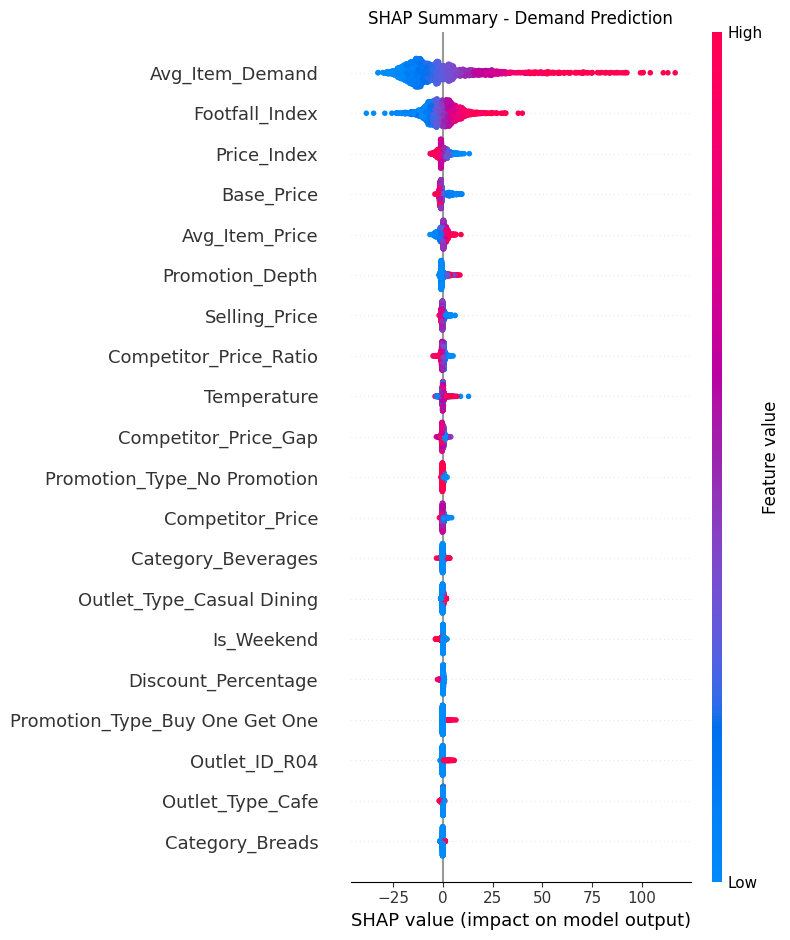

In [7]:
shap.summary_plot(shap_values, sample_X_processed, max_display=20, show=False)
plt.title("SHAP Summary - Demand Prediction")
plt.tight_layout()
plt.show()

## Importance by business theme

Several features describe the same thing (for example four features describe our price). Adding their
SHAP values gives a clearer picture of what matters.

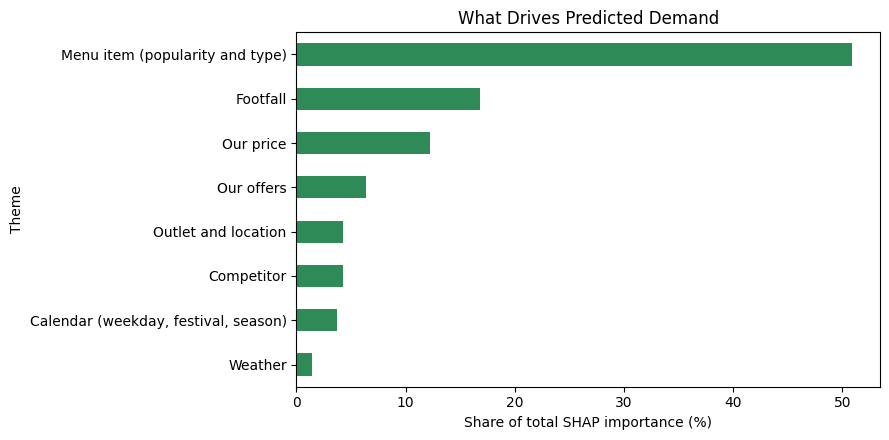

Theme
Menu item (popularity and type)         50.9
Footfall                                16.8
Our price                               12.2
Our offers                               6.4
Competitor                               4.3
Outlet and location                      4.3
Calendar (weekday, festival, season)     3.7
Weather                                  1.4
Name: Mean_Abs_SHAP, dtype: float64

In [8]:
def theme(feature):
    if feature in ("Avg_Item_Demand", "Avg_Item_Price") or feature.startswith(("Item_ID_", "Category_", "Food_Type_")):
        return "Menu item (popularity and type)"
    if feature.startswith(("Outlet_ID_", "City_", "Outlet_Type_", "Location_Type_")):
        return "Outlet and location"
    if feature in ("Selling_Price", "Price_Index", "Base_Price"):
        return "Our price"
    if feature.startswith("Promotion_") or feature == "Discount_Percentage":
        return "Our offers"
    if feature.startswith("Competitor_"):
        return "Competitor"
    if feature == "Footfall_Index":
        return "Footfall"
    if feature.startswith(("Day_of_Week_", "Festival_", "Season_")) or feature in (
            "Is_Weekend", "Holiday_Flag", "Month", "Quarter", "Week", "Day_of_Month", "Month_Sin", "Month_Cos", "Week_Sin", "Week_Cos"):
        return "Calendar (weekday, festival, season)"
    if feature in ("Temperature", "Rainfall"):
        return "Weather"
    return "Other"

shap_importance["Theme"] = shap_importance["Feature"].map(theme)
theme_importance = shap_importance.groupby("Theme")["Mean_Abs_SHAP"].sum().sort_values(ascending=False)
theme_share = (theme_importance / theme_importance.sum() * 100).astype(float).round(1)

plt.figure(figsize=(9, 4.5))
theme_share.sort_values().plot(kind="barh", color="seagreen")
plt.xlabel("Share of total SHAP importance (%)")
plt.title("What Drives Predicted Demand")
plt.tight_layout()
plt.show()
theme_share

## Top demand drivers in business language

In [9]:
def interpret(feature):
    fixed = {
        "Avg_Item_Demand": "Strongest predictor: how well this item normally sells at this outlet sets the baseline.",
        "Footfall_Index": "More guests in the outlet means more orders of every item.",
        "Price_Index": "Price relative to the item's base price: a higher price lowers predicted demand.",
        "Selling_Price": "The price the customer pays: a higher price lowers predicted demand.",
        "Base_Price": "Expensive items sell in lower volumes than cheap add-ons such as breads.",
        "Discount_Percentage": "Deeper advertised discounts raise predicted demand.",
        "Promotion_Depth": "The more value an offer hands to the customer, the higher the predicted demand.",
        "Promotion_Flag": "Running any offer raises predicted demand.",
        "Is_Weekend": "Weekends change demand; the direction depends on the outlet's location.",
        "Holiday_Flag": "Festival days change demand.",
        "Temperature": "Hot days lift cold beverages and kulfi; cold days lift chai and gajar halwa.",
        "Rainfall": "Rain keeps dine-in guests away and pushes delivery orders up.",
        "Competitor_Price": "A cheaper competitor pulls orders away.",
        "Competitor_Price_Ratio": "Our price relative to the competitor: the more expensive we are, the lower the demand.",
        "Competitor_Price_Gap": "Rupee gap to the competitor: the more expensive we are, the lower the demand.",
        "Competitor_Discount": "Competitor discounts reduce our demand.",
        "Competitor_Promotion_Flag": "A competitor offer reduces our demand.",
        "Avg_Item_Price": "The item's usual price level at this outlet.",
        "Day_of_Month": "Demand is higher just after payday and softer at month end.",
    }
    if feature in fixed:
        return fixed[feature]
    prefixes = {
        "Promotion_Type_": "This offer type changes predicted demand compared with other offers.",
        "Day_of_Week_": "This weekday has its own demand level.",
        "Festival_": "This festival (or its absence) shifts demand.",
        "Season_": "Seasonal demand pattern.",
        "Outlet_Type_": "The outlet format changes which items sell.",
        "Location_Type_": "The location type changes the weekday / weekend pattern.",
        "Outlet_ID_": "Outlet-specific demand level.",
        "City_": "City-specific demand level.",
        "Category_": "Menu category sets the typical volume.",
        "Item_ID_": "Item-specific demand level.",
        "Food_Type_": "Veg and non-veg items follow different patterns (for example Tuesdays).",
    }
    for prefix, text in prefixes.items():
        if feature.startswith(prefix):
            return text
    return "Captures recurring seasonal demand patterns."

top_10_features = shap_importance.head(10)[["Feature", "Mean_Abs_SHAP"]].copy()
top_10_features["Business_Interpretation"] = top_10_features["Feature"].map(interpret)
top_10_features["Feature"] = top_10_features["Feature"].str.replace("_", " ", regex=False)
top_10_features["Mean_Abs_SHAP"] = top_10_features["Mean_Abs_SHAP"].round(3)

pd.set_option("display.max_colwidth", 120)
top_10_features

,Feature,Mean_Abs_SHAP,Business_Interpretation
0,Avg Item Demand,14.944,Strongest predictor: how well this item normally sells at this outlet sets the baseline.
1,Footfall Index,5.953,More guests in the outlet means more orders of every item.
2,Price Index,1.978,Price relative to the item's base price: a higher price lowers predicted demand.
3,Base Price,1.696,Expensive items sell in lower volumes than cheap add-ons such as breads.
4,Avg Item Price,1.367,The item's usual price level at this outlet.
5,Promotion Depth,1.127,"The more value an offer hands to the customer, the higher the predicted demand."
6,Selling Price,0.641,The price the customer pays: a higher price lowers predicted demand.
7,Competitor Price Ratio,0.584,"Our price relative to the competitor: the more expensive we are, the lower the demand."
8,Temperature,0.447,Hot days lift cold beverages and kulfi; cold days lift chai and gajar halwa.
9,Competitor Price Gap,0.435,"Rupee gap to the competitor: the more expensive we are, the lower the demand."


In [10]:
top_10_features.to_csv("../data/shap_business_insights.csv", index=False)

print("SHAP business insights saved successfully.")
print("Rows saved:", len(top_10_features))

SHAP business insights saved successfully.
Rows saved: 10


## How one prediction is built

In [11]:
row = 0
contributions = (
    pd.DataFrame({"Feature": processed_feature_names, "Value": sample_X_processed.iloc[row].to_numpy(), "SHAP": shap_values[row]})
    .assign(Abs=lambda d: d["SHAP"].abs())
    .sort_values("Abs", ascending=False)
    .head(8)
    .drop(columns="Abs")
)
base_value = float(np.ravel(explainer.expected_value)[0])

print("Item:", sample_X.iloc[row]["Item_ID"], "| Outlet:", sample_X.iloc[row]["Outlet_ID"],
      "|", sample_X.iloc[row]["Day_of_Week"], "|", sample_X.iloc[row]["Promotion_Type"])
print("Average prediction (starting point):", round(base_value, 1), "units")
print("Prediction for this row            :", round(base_value + shap_values[row].sum(), 1), "units")
contributions.round(2)

Item: M01 | Outlet: R08 | Monday | No Promotion
Average prediction (starting point): 33.7 units
Prediction for this row            : 10.4 units


,Feature,Value,SHAP
113,Avg_Item_Demand,14.59,-14.53
91,Footfall_Index,0.83,-4.15
110,Price_Index,1.05,-1.49
92,Base_Price,290.00,-1.35
114,Avg_Item_Price,282.95,1.30
96,Promotion_Depth,0.00,-0.62
93,Selling_Price,304.00,-0.49
74,Outlet_Type_Cafe,1.00,-0.43


## Model performance (from Notebook 3)

In [12]:
model_performance = pd.read_csv("../data/model_performance_summary.csv")
model_performance

,Model,MAE,RMSE,R2
0,XGBoost,4.632,6.320,0.938
1,Random Forest,4.970,6.811,0.928
2,Linear Regression,6.364,8.927,0.876


## Findings

In [13]:
top = shap_importance.iloc[0]
print(f"1. The strongest driver is {top['Feature'].replace('_', ' ')} (average impact {top['Mean_Abs_SHAP']:.1f} units).")
print("2. Share of total importance by theme: " + "; ".join(f"{t} {s:.0f}%" for t, s in theme_share.items()) + ".")
print(f"3. Price and offers together account for {theme_share.get('Our price', 0) + theme_share.get('Our offers', 0):.0f}% - "
      "these are the levers the restaurant controls, and the ones the optimiser moves.")
print("4. SHAP values show how the model uses each feature; they are not proof of cause and effect.")

1. The strongest driver is Avg Item Demand (average impact 14.9 units).
2. Share of total importance by theme: Menu item (popularity and type) 51%; Footfall 17%; Our price 12%; Our offers 6%; Competitor 4%; Outlet and location 4%; Calendar (weekday, festival, season) 4%; Weather 1%.
3. Price and offers together account for 19% - these are the levers the restaurant controls, and the ones the optimiser moves.
4. SHAP values show how the model uses each feature; they are not proof of cause and effect.
